# 09 – Unseen promotions: when the test contains something training never did

| Submission | Method | Backtest RMSLE | Kaggle |
|---|---|---|---|
| v3 | LightGBM, closed days fixed | 0.443 | 0.40358 |
| v4 | v3 + promotions (notebook 08) | 0.419 | **0.41332** |

Promotions improved the backtest in all 8 windows, yet v4 scored worse than v3 on Kaggle. The second time Kaggle
disagrees with the backtest (the first was notebook 07). We follow the same checklist:
don't tune; compare with a submission we trust; look for concentration.

**Plan:**
1. Where do v3 and v4 disagree?
2. What's special about 16 August?
3. Confirming it with one diagnostic submission.
4. A rule decided from training data only.
5. What the rule costs in the backtest, and why that's expected.
6. Submission v5.

*Running time: about 10 minutes (one backtest).*

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import load_test, load_train
from src.dataset import build_table
from src.features import load_holidays, load_stores
from src.model import TRAIN_START, backtest_model, fit, forecast, guard_unseen_promotions, prepare
from src.validation import make_cutoffs

IMAGES = "../images"

train = load_train()
test = load_test()
wide = train.pivot_table(index="date", columns=["store_nbr", "family"], values="sales", observed=True)

## 1. Where do v3 and v4 disagree?

In [2]:
v3 = pd.read_csv("../submissions/v3_lightgbm_closed_stores.csv")
v4 = pd.read_csv("../submissions/v4_lightgbm_promo.csv")
both = test.merge(v3, on="id").merge(v4, on="id", suffixes=("_v3", "_v4"))
both["log_diff"] = np.log1p(both["sales_v4"]) - np.log1p(both["sales_v3"])
both["squared"] = both["log_diff"] ** 2

by_family = both.groupby("family", observed=True)["squared"].sum()
print("Share of the v3-v4 difference, by family:")
print((by_family / by_family.sum()).sort_values(ascending=False).head(5).round(3).to_string())
print("\nMean log difference (v4 - v3), by date:")
print(both.groupby("date")["log_diff"].mean().round(3).to_string())

Share of the v3-v4 difference, by family:
family
SCHOOL AND OFFICE SUPPLIES    0.536
LAWN AND GARDEN               0.166
LINGERIE                      0.151
BEAUTY                        0.040
HOME AND KITCHEN II           0.026

Mean log difference (v4 - v3), by date:
date
2017-08-16    0.201
2017-08-17    0.009
2017-08-18    0.015
2017-08-19    0.011
2017-08-20    0.018
2017-08-21    0.014
2017-08-22    0.016
2017-08-23    0.012
2017-08-24    0.005
2017-08-25    0.008
2017-08-26    0.013
2017-08-27    0.015
2017-08-28    0.010
2017-08-29    0.010
2017-08-30    0.019
2017-08-31    0.011


Three families cause most of the difference, and **one date stands out: 16 August**, the first test day,
where v4 is far above v3. On every other day the two are close.

## 2. What's special about 16 August?

The obvious suspect is the new input: promotions. **Breadth** = the share of stores with a promotion in a family on a day.

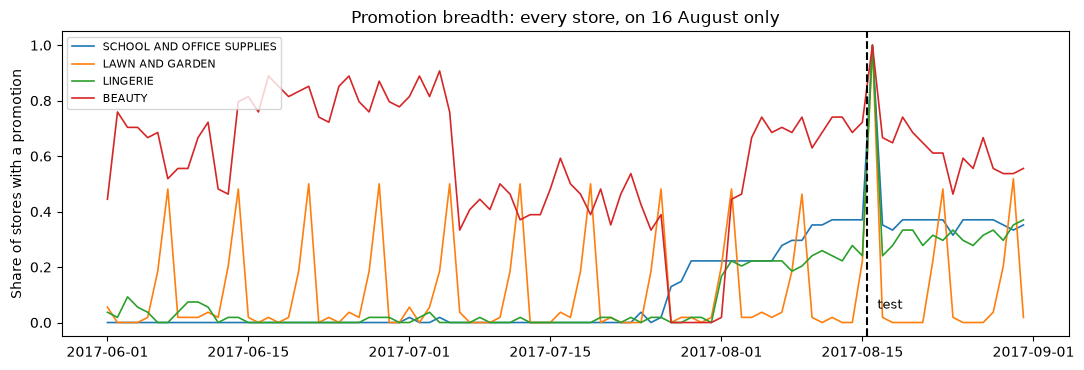

,16 August,highest in training
family,,
SCHOOL AND OFFICE SUPPLIES,1.0,0.67
LAWN AND GARDEN,1.0,0.52
LINGERIE,1.0,0.56
BEAUTY,1.0,0.91


In [3]:
rows = pd.concat([train, test])
rows["family"] = rows["family"].astype(str)
breadth = rows.assign(promoted=rows["onpromotion"] > 0).groupby(["date", "family"])["promoted"].mean().unstack()

families = ["SCHOOL AND OFFICE SUPPLIES", "LAWN AND GARDEN", "LINGERIE", "BEAUTY"]
fig, ax = plt.subplots(figsize=(11, 3.8))
for family in families:
    ax.plot(breadth.loc["2017-06-01":, family], label=family, linewidth=1.2)
ax.axvline(pd.Timestamp("2017-08-15 12:00"), color="black", linestyle="--")
ax.text(pd.Timestamp("2017-08-16 12:00"), 0.05, "test", fontsize=9)
ax.set_ylabel("Share of stores with a promotion")
ax.set_title("Promotion breadth: every store, on 16 August only")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(f"{IMAGES}/promotion_breadth.png", dpi=120)
plt.show()

training_max = breadth.loc[TRAIN_START:"2017-08-15", families].max()
pd.DataFrame({"16 August": breadth.loc["2017-08-16", families], "highest in training": training_max}).round(2)

On 16 August **every** store has a promotion in these families. In training, the highest share ever was 52–91%.
We can't tell from the data whether it was a real one-day promotion event or an oddity in the test file; it doesn't matter:
**the model had never seen it.**

And tree models can't extrapolate. A tree splits the data into regions seen in training and gives each region one value;
a new combination of features lands in whatever region the splits send it to. Here the model saw "promotions in every
store" and forecast like for the most-promoted series it knew, which (for school supplies) were in the middle of
back-to-school, with sales many times normal:

In [4]:
day = both[(both["date"] == "2017-08-16") & both["family"].isin(families)]
print(f"{len(day)} rows ({len(day) / len(both):.1%} of the test) carry "
      f"{day['squared'].sum() / both['squared'].sum():.0%} of the v3-v4 difference")
day.groupby("family", observed=True)[["onpromotion", "sales_v3", "sales_v4"]].median().round(1)

216 rows (0.8% of the test) carry 60% of the v3-v4 difference


,onpromotion,sales_v3,sales_v4
family,,,
BEAUTY,2.0,3.2,5.3
LAWN AND GARDEN,16.0,5.2,38.4
LINGERIE,5.0,4.3,13.3
SCHOOL AND OFFICE SUPPLIES,14.0,1.1,36.6


## 3. Confirming it with one diagnostic submission

We can't check the true sales of 16 August. But we can test the hypothesis once: **v4b** = v4 with only the
16 August rows of three families (LAWN AND GARDEN, LINGERIE, SCHOOL AND OFFICE SUPPLIES, 162 rows) replaced by v3's forecasts.

| Submission | Kaggle |
|---|---|
| v3 | 0.40358 |
| v4 | 0.41332 |
| **v4b** (diagnostic) | **0.38560** |

**Confirmed.** Those 162 rows (0.6% of the test) cost about 0.028, and promotions help everywhere else
(v4b is 0.018 better than v3, close to the backtest's 0.024).

*Why this was acceptable, once:* we tested **one** specific hypothesis. Trying many variations on Kaggle until the score
improves would be tuning on the test set. But v4b isn't a real model either: the rows were chosen by looking at the
leaderboard, which isn't possible in real forecasting. We need a rule.

## 4. A rule decided from training data only

`guard_unseen_promotions` in `src/model.py`:
1. compute the breadth for each (date, family);
2. for each family, the **highest breadth in the training period** (up to the cutoff);
3. after the cutoff, a (date, family) above that maximum is **unseen**; on its rows, the promotion features are set to
   "promotions as usual": `promo` = its recent level, `promo_vs_recent` = 0.

The model itself is unchanged: only the inputs of unseen situations are replaced by something it knows.
`tests/test_model.py` checks the rule on a tiny example.

What does it flag in the test?

In [5]:
table = build_table(train, load_stores(), load_holidays(), end="2017-08-31", extras=("promo",), test=test)
data = prepare(table)
guarded, unseen = guard_unseen_promotions(data, "2017-08-15")
unseen.round(2).rename("breadth").to_frame()

breadth
date       family                             
2017-08-16 BEAUTY                          1.0
           LAWN AND GARDEN                 1.0
           LINGERIE                        1.0
           SCHOOL AND OFFICE SUPPLIES      1.0

Exactly the 16 August cases, found without looking at any Kaggle score, plus **BEAUTY**, which the manual v4b missed
(100% of stores, against a training maximum of 91%).

## 5. What does the rule cost in the backtest?

A rule must also be checked where it might do harm. Same 8 windows as before, with the guard switched on
(about 7 minutes):

In [6]:
cutoffs = make_cutoffs(wide.index.max(), n_windows=8)
guarded_scores, _ = backtest_model(data, wide, cutoffs, guard=True)

without_guard = [0.5830, 0.4153, 0.4118, 0.3901, 0.3822, 0.3746, 0.3963, 0.4017]  # notebook 08, promotions
result = pd.DataFrame({"no guard": without_guard, "guard": guarded_scores["RMSLE"],
                       "(date, family) flagged": guarded_scores["flagged"].astype(int)}, index=guarded_scores.index)
result["change"] = result["guard"] - result["no guard"]
print(f"Mean: {result['no guard'].mean():.4f} without the guard, {result['guard'].mean():.4f} with it")
result.round(4)

Mean: 0.4194 without the guard, 0.4219 with it


,no guard,guard,"(date, family) flagged",change
window starts,,,,
2017-04-10,0.5830,0.5961,57,0.0131
2017-04-26,0.4153,0.4165,6,0.0012
2017-05-12,0.4118,0.4172,9,0.0054
2017-05-28,0.3901,0.3903,2,0.0002
2017-06-13,0.3822,0.3822,0,0.0000
2017-06-29,0.3746,0.3745,1,-0.0001
2017-07-15,0.3963,0.3963,0,-0.0000
2017-07-31,0.4017,0.4017,0,0.0000


**The guard costs a little in the backtest** (about +0.0025 on average), all of it in the windows where it fires.
Why? Most likely because promotions grew steadily from 2014 to 2017, so a "new record" breadth is often just
**normal growth**, and the model handled those days well. Neutralising them threw away useful information.

How far above the training maximum were those cases, compared with 16 August?

In [7]:
excess = []
for cutoff in cutoffs:
    seen_max = breadth.loc[TRAIN_START:cutoff].max()
    window = breadth.loc[cutoff + pd.Timedelta(days=1): cutoff + pd.Timedelta(days=16)]
    over = (window - seen_max).stack()
    excess.append(over[over > 0])
excess = pd.concat(excess)
print(f"Backtest windows: {len(excess)} flagged (date, family), exceeding the maximum by "
      f"{excess.median():.2f} at the median and {excess.max():.2f} at most")
test_excess = (breadth.loc["2017-08-16", families] - training_max).round(2)
print("16 August:", test_excess.to_dict())

Backtest windows: 75 flagged (date, family), exceeding the maximum by 0.02 at the median and 0.13 at most
16 August: {'SCHOOL AND OFFICE SUPPLIES': 0.33, 'LAWN AND GARDEN': 0.48, 'LINGERIE': 0.44, 'BEAUTY': 0.09}


In the backtest, flagged cases exceed the old maximum only slightly (at most 0.13). On 16 August, three families exceed
it by 0.33–0.48, far beyond that; BEAUTY only by 0.09. A threshold ("flag only large jumps") would separate the three big
cases, though not BEAUTY. But **we won't tune that threshold**: we already know from the leaderboard
which answer helps, so any threshold we picked now would be fitted to the test, not chosen on principle.

### Insurance

The guard is **insurance**. Insurance costs a premium in normal times and pays out in rare bad ones.
- The backtest can only measure the **premium** (+0.0025), because none of its windows contains the rare event.
- The test showed the **payout** (about 0.028 for v4b).

This is a general limit of validation: **it can't measure protection against situations it doesn't contain.**
Whether to buy the insurance is a judgement call. Here we keep it, and we're honest that the decision was informed
by the leaderboard: a fully independent check would need new data with a similar event.

## 6. Submission v5

In [8]:
final_model, final_trees = fit(data, "2017-08-15")
test_dates = pd.DatetimeIndex(sorted(test["date"].unique()), name="date")
predicted = forecast(final_model, guarded, test_dates)

long = predicted.unstack().rename("sales").reset_index()
v5 = test.merge(long, on=["store_nbr", "family", "date"], how="left")[["id", "sales"]]
assert len(v5) == len(test) and v5["sales"].notna().all() and (v5["sales"] >= 0).all()
v5.to_csv("../submissions/v5_lightgbm_promo_guard.csv", index=False)

check = test.merge(v5, on="id").merge(v4.rename(columns={"sales": "v4"}), on="id")
flagged_rows = (check["date"] == "2017-08-16") & check["family"].isin(families)
print(f"Trees: {final_trees}; rows different from v4: {int((~np.isclose(check['sales'], check['v4'])).sum())}")
check[flagged_rows].groupby("family", observed=True)[["v4", "sales"]].median().round(1).rename(columns={"sales": "v5"})

Trees: 1296; rows different from v4: 216


,v4,v5
family,,
BEAUTY,5.3,3.3
LAWN AND GARDEN,38.4,5.0
LINGERIE,13.3,4.2
SCHOOL AND OFFICE SUPPLIES,36.6,0.5


v5 differs from v4 only on the 216 flagged rows (4 families × 54 stores), where its forecasts are back to normal levels.
### Kaggle result

| Submission | Kaggle |
|---|---|
| v3 (no promotions) | 0.40358 |
| v4 (promotions) | 0.41332 |
| v4b (diagnostic, rows chosen by hand) | 0.38560 |
| **v5 (promotions + guard)** | **0.38988** |

The rule recovers most of the diagnostic's gain (0.014 better than v3), without choosing rows by looking at the
leaderboard. v5 is 0.004 behind v4b. The two differ in two ways: v5 also changes BEAUTY, and its guarded rows are
forecast by the model with "usual" promotions instead of being copied from v3. Finding out which one costs the 0.004
would mean more submissions aimed at the same 216 rows: tuning on the leaderboard, so we stop here.
It's still not a clean out-of-sample test, for the reason above.

## Summary

| Finding | Consequence |
|---|---|
| 162 rows on 16 August (0.6% of the test) cost v4 about 0.028 | A few extreme errors dominate a squared-error metric |
| Every store had a promotion; never more than 52–91% in training | Tree models can't extrapolate: unseen inputs get arbitrary forecasts |
| A rule from training data finds the same days (plus BEAUTY) | `guard_unseen_promotions`, tested |
| The rule costs +0.0025 in the backtest | Validation measures the premium of insurance, not the payout |
| The decision was informed by the leaderboard | Say so; don't tune thresholds on it |
| v5 scored 0.38988, best real model so far | A rule from training data recovers most of the hand-picked gain |

**A habit worth keeping:** before submitting, compare the test inputs with the training inputs, not just column by
column, but in combinations that matter (like "share of stores on promotion"). Unusual test data is cheaper to find
before the leaderboard does.